# FMCG lakehouse: querying GCS through Hive with PySpark

Run this notebook with the **FMCG PySpark (Spark 4.0.1, GCS + Hive)** kernel. When the kernel starts, it creates:
- `spark`: a SparkSession with the Google Cloud Storage connector and the Hive metastore (the same settings as the pipeline jobs);
- `F`: `pyspark.sql.functions`.

Two Hive databases are available:

| Database | Bucket | Partitions |
|---|---|---|
| `datalake` | `gs://fmcg-datalake` | `year`, `month`, `day` |
| `mart` | `gs://fmcg-mart` | `year`, `week` (ISO) |

Shell cells such as `!gsutil ls -lh gs://fmcg-datalake/` browse the buckets (section 6).

Always filter on the partition columns: Spark then reads only those GCS folders.

In [1]:
spark.version, spark.catalog.currentDatabase()

('4.0.1', 'default')

## 0. Configure the notebook for GCS (`gsutil`, `gcloud storage`, Spark)

This cell points the Google Cloud CLI at the project's GCS: the local emulator by default, or real GCS when `GCS_MODE=real`.
- It creates (once) a separate gcloud configuration called `fmcg-emulator` and selects it **only for this notebook**, so your default gcloud setup is not changed.
- It makes `gsutil` run through `gcloud storage`, which supports the emulator endpoint.
- It reuses the `spark` session the kernel started; if this notebook runs on another kernel, it creates one.

In [2]:
import os, subprocess, sys
from pathlib import Path

REPO = Path(os.environ.get("FMCG_REPO", Path.cwd().parent)).resolve()
sys.path.insert(0, str(REPO))
GCS_MODE = os.environ.setdefault("GCS_MODE", "emulator")

if GCS_MODE == "emulator":
    # one-time: named gcloud configuration "fmcg-emulator" -> http://localhost:4443 (no login needed)
    subprocess.run([str(REPO / "scripts" / "setup_gcloud_emulator.sh")], check=True, capture_output=True)
    os.environ["CLOUDSDK_ACTIVE_CONFIG_NAME"] = "fmcg-emulator"        # only this notebook's shell commands use it
    os.environ["BOTO_CONFIG"] = str(REPO / ".gcloud" / "boto.cfg")      # gsutil -> gcloud storage (emulator-aware)
else:
    os.environ.pop("CLOUDSDK_ACTIVE_CONFIG_NAME", None)                 # real GCS: your normal gcloud login/project
os.environ["CLOUDSDK_COMPONENT_MANAGER_DISABLE_UPDATE_CHECK"] = "1"     # no "updates available" banner in outputs

if "spark" not in globals():                                           # kernel already created it; other kernels: create now
    from common.config import get_spark
    from pyspark.sql import functions as F
    spark = get_spark("jupyter-fmcg")

print("GCS mode         :", GCS_MODE)
print("gcloud config    :", os.environ.get("CLOUDSDK_ACTIVE_CONFIG_NAME", "default"))
print("spark            :", spark.version)

GCS mode         : emulator
gcloud config    : fmcg-emulator
spark            : 4.0.1


In [3]:
!gcloud storage ls
!gsutil ls -lh gs://fmcg-datalake/

gs://fmcg-datalake/


gs://fmcg-landing/
gs://fmcg-mart/


Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.


                                  gs://fmcg-datalake/_manifests/
                                  gs://fmcg-datalake/customers/
                                  gs://fmcg-datalake/promotions/
                                  gs://fmcg-datalake/stores/
                                  gs://fmcg-datalake/transactions/
TOTAL: 0 objects, 0 bytes (0 B)


## 1. What is in each layer (`spark.sql(...).show(10, 0)`)

In [4]:
spark.sql("show databases").show(10, 0)
spark.sql("show tables in datalake").show(10, 0)
spark.sql("show tables in mart").show(10, 0)

+---------+
|namespace|
+---------+
|datalake |
|default  |
|mart     |
+---------+



+---------+------------+-----------+
|namespace|tableName   |isTemporary|
+---------+------------+-----------+
|datalake |customers   |false      |
|datalake |promotions  |false      |
|datalake |stores      |false      |
|datalake |transactions|false      |
+---------+------------+-----------+

+---------+------------------------------+-----------+
|namespace|tableName                     |isTemporary|
+---------+------------------------------+-----------+
|mart     |category_brand_weekly         |false      |
|mart     |customer_tier_weekly          |false      |
|mart     |fact_sales                    |false      |
|mart     |promotion_weekly_effectiveness|false      |
|mart     |store_weekly_performance      |false      |
+---------+------------------------------+-----------+



In [5]:
spark.sql("show partitions mart.fact_sales").show(10, 0)

+-----------------+
|partition        |
+-----------------+
|year=2026/week=44|
|year=2026/week=45|
+-----------------+



In [6]:
# where a table's files live in GCS, and how it is stored
spark.sql("describe formatted mart.store_weekly_performance") \
     .where("col_name in ('Type', 'Provider', 'Location', 'Partition Provider')") \
     .show(10, 0)

+------------------+---------------------------------------+-------+
|col_name          |data_type                              |comment|
+------------------+---------------------------------------+-------+
|Type              |EXTERNAL                               |       |
|Provider          |hive                                   |       |
|Location          |gs://fmcg-mart/store_weekly_performance|       |
|Partition Provider|Catalog                                |       |
+------------------+---------------------------------------+-------+



## 2. Raw datalake with `spark.table(...)`

In [7]:
tx = spark.table("datalake.transactions")
tx.printSchema()

root
 |-- transaction_id: string (nullable = true)
 |-- line_no: integer (nullable = true)
 |-- transaction_ts: timestamp (nullable = true)
 |-- store_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- sku: string (nullable = true)
 |-- product_name: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- category: string (nullable = true)
 |-- sub_category: string (nullable = true)
 |-- pack_size: string (nullable = true)
 |-- quantity: integer (nullable = true)
 |-- unit_price: decimal(12,2) (nullable = true)
 |-- discount_amount: decimal(12,2) (nullable = true)
 |-- promotion_id: string (nullable = true)
 |-- payment_mode: string (nullable = true)
 |-- channel: string (nullable = true)
 |-- _source_file: string (nullable = true)
 |-- _ingested_at: timestamp (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- day: integer (nullable = true)



In [8]:
# one day's raw POS lines (partition pruning: only gs://fmcg-datalake/transactions/year=2026/month=11/day=8/ is read)
tx.where("year = 2026 and month = 11 and day = 8") \
  .select("transaction_id", "line_no", "transaction_ts", "store_id", "customer_id", "product_name", "quantity", "unit_price", "discount_amount", "promotion_id") \
  .show(10, 0)

+----------------+-------+-------------------+--------+-----------+------------------+--------+----------+---------------+------------+
|transaction_id  |line_no|transaction_ts     |store_id|customer_id|product_name      |quantity|unit_price|discount_amount|promotion_id|
+----------------+-------+-------------------+--------+-----------+------------------+--------+----------+---------------+------------+
|T202611080140063|4      |2026-11-08 20:23:16|ST014   |CU000161   |Sandal Glow Soap  |1       |180.00    |0.00           |NULL        |
|T202611080010030|4      |2026-11-08 18:00:32|ST001   |NULL       |Basmati Rice      |4       |650.00    |260.00         |PR004       |
|T202611080050000|1      |2026-11-08 19:34:00|ST005   |CU001077   |Atta Noodles      |1       |70.00     |0.00           |NULL        |
|T202611080350037|3      |2026-11-08 11:04:55|ST035   |CU000603   |Room Freshener    |1       |225.00    |0.00           |NULL        |
|T202611080360031|3      |2026-11-08 18:38:27|ST

In [9]:
# lines and gross value per drop date, with the DataFrame API
(tx.groupBy("year", "month", "day")
   .agg(F.count("*").alias("lines"),
        F.round(F.sum(F.col("quantity") * F.col("unit_price")), 0).alias("gross_inr"))
   .orderBy("year", "month", "day")
   .show(14, 0))

+----+-----+---+-----+---------+
|year|month|day|lines|gross_inr|
+----+-----+---+-----+---------+
|2026|10   |26 |2796 |1082387  |
|2026|10   |27 |2851 |1097143  |
|2026|10   |28 |2970 |1167366  |
|2026|10   |29 |3052 |1217004  |
|2026|10   |30 |2988 |1276058  |
|2026|10   |31 |4025 |1681067  |
|2026|11   |1  |3932 |1615374  |
|2026|11   |2  |3233 |1365261  |
|2026|11   |3  |3459 |1461042  |
|2026|11   |4  |3474 |1458202  |
|2026|11   |5  |4072 |1727187  |
|2026|11   |6  |3943 |1704675  |
|2026|11   |7  |6153 |2588587  |
|2026|11   |8  |7155 |3037922  |
+----+-----+---+-----+---------+



## 3. Business questions on the mart with `spark.sql(...)`

In [10]:
spark.sql("""
    select week, region,
           round(sum(net_sales))           as net_sales_inr,
           round(sum(prev_week_net_sales)) as prev_week_inr,
           round(100 * (sum(net_sales) / sum(prev_week_net_sales) - 1), 1) as wow_pct
    from mart.store_weekly_performance
    where year = 2026
    group by week, region
    order by week, net_sales_inr desc
""").show(10, 0)

+----+------+-------------+-------------+-------+
|week|region|net_sales_inr|prev_week_inr|wow_pct|
+----+------+-------------+-------------+-------+
|44  |North |3552398      |NULL         |NULL   |
|44  |South |2425570      |NULL         |NULL   |
|44  |West  |1754524      |NULL         |NULL   |
|44  |East  |859866       |NULL         |NULL   |
|45  |North |5052937      |3552398      |42.2   |
|45  |South |3327153      |2425570      |37.2   |
|45  |West  |2479214      |1754524      |41.3   |
|45  |East  |1268498      |859866       |47.5   |
+----+------+-------------+-------------+-------+



In [11]:
# top stores in the Diwali week (ISO week 45), using spark.table + DataFrame API
(spark.table("mart.store_weekly_performance")
      .where("year = 2026 and week = 45")
      .select("store_name", "region", "store_format", "net_sales", "avg_basket_value", "sales_per_sqft", "wow_growth_pct", "rank_in_region")
      .orderBy(F.desc("net_sales"))
      .show(10, 0))

+------------------------+------+------------+---------+----------------+--------------+--------------+--------------+
|store_name              |region|store_format|net_sales|avg_basket_value|sales_per_sqft|wow_growth_pct|rank_in_region|
+------------------------+------+------------+---------+----------------+--------------+--------------+--------------+
|Lucknow Hypermarket 11  |North |Hypermarket |712178.15|1399.17         |23.02         |45.3          |1             |
|Jaipur Hypermarket 13   |North |Hypermarket |627139.08|1261.85         |16.45         |16.05         |2             |
|Jaipur Hypermarket 14   |North |Hypermarket |625436.00|1353.76         |15.67         |62.41         |3             |
|Gurugram Hypermarket 6  |North |Hypermarket |605545.59|1366.92         |11.06         |30.7          |4             |
|Bengaluru Hypermarket 30|South |Hypermarket |575852.11|1358.14         |10.60         |20.65         |1             |
|Kochi Hypermarket 40    |South |Hypermarket |57

In [12]:
spark.sql("""
    select category,
           round(sum(net_sales)) as net_sales_inr,
           round(100 * sum(net_sales) / sum(sum(net_sales)) over (), 1) as share_pct,
           round(100 * (sum(net_sales) / sum(prev_week_net_sales) - 1), 1) as wow_pct
    from mart.category_brand_weekly
    where year = 2026 and week = 45
    group by category
    order by net_sales_inr desc
""").show(10, 0)

+-------------+-------------+---------+-------+
|category     |net_sales_inr|share_pct|wow_pct|
+-------------+-------------+---------+-------+
|Foods        |4466894      |36.8     |44.2   |
|Personal Care|2387194      |19.7     |34.2   |
|Beverages    |1997681      |16.5     |39.0   |
|Home Care    |1828045      |15.1     |32.5   |
|Dairy        |1447989      |11.9     |61.0   |
+-------------+-------------+---------+-------+



In [13]:
# did the promotions pay for their discount?
spark.sql("""
    select week, promo_name, brand, discount_pct, promo_units, unit_uplift_pct,
           discount_cost, incremental_net_sales, roi
    from mart.promotion_weekly_effectiveness
    where year = 2026
    order by week, roi desc
""").show(10, 0)

+----+---------------------+--------------+------------+-----------+---------------+-------------+---------------------+----+
|week|promo_name           |brand         |discount_pct|promo_units|unit_uplift_pct|discount_cost|incremental_net_sales|roi |
+----+---------------------+--------------+------------+-----------+---------------+-------------+---------------------+----+
|44  |Diwali Sweets Bonanza|Mithas        |20          |1514       |65.9           |158134.20    |251197.33            |1.59|
|44  |Chai Time            |Chaiwala      |25          |1327       |58.7           |148765.00    |165132.51            |1.11|
|44  |Festive Clean Home   |Kleanso       |15          |2121       |NULL           |47396.85     |NULL                 |NULL|
|44  |Brightex Wash Week   |Brightex      |10          |2096       |NULL           |62117.20     |NULL                 |NULL|
|44  |Glow Up Personal Care|Aurelle       |18          |2077       |NULL           |87113.70     |NULL                

In [14]:
spark.table("mart.customer_tier_weekly").where("year = 2026 and week = 45") \
     .orderBy(F.desc("net_sales")).show(10, 0)

+--------------+------------+----------------+-------+-----+----------+----------------------+------------------------+------------------+----+----+
|customer_type |loyalty_tier|active_customers|baskets|units|net_sales |avg_spend_per_customer|avg_baskets_per_customer|share_of_sales_pct|year|week|
+--------------+------------+----------------+-------+-----+----------+----------------------+------------------------+------------------+----+----+
|walk-in       |Walk-in     |0               |2708   |16608|3732879.62|NULL                  |NULL                    |30.78             |2026|45  |
|loyalty member|Bronze      |1069            |2773   |16802|3645279.51|3409.99               |2.59                    |30.06             |2026|45  |
|loyalty member|Silver      |696             |1905   |11298|2534076.60|3640.91               |2.74                    |20.89             |2026|45  |
|loyalty member|Gold        |398             |1066   |6475 |1431987.08|3597.96               |2.68        

## 4. Mixing both styles: a DataFrame registered as a temporary view

In [15]:
daily = (spark.table("mart.fact_sales")
              .where("year = 2026")
              .groupBy("sale_date", "day_of_week")
              .agg(F.round(F.sum("net_amount"), 0).alias("net_sales_inr"),
                   F.countDistinct("transaction_id").alias("baskets")))
daily.createOrReplaceTempView("daily_sales")

spark.sql("""
    select sale_date, day_of_week, net_sales_inr, baskets,
           round(net_sales_inr / baskets, 0) as avg_basket_inr
    from daily_sales
    order by sale_date
""").show(14, 0)

+----------+-----------+-------------+-------+--------------+
|sale_date |day_of_week|net_sales_inr|baskets|avg_basket_inr|
+----------+-----------+-------------+-------+--------------+
|2026-10-26|Monday     |1052992      |769    |1369          |
|2026-10-27|Tuesday    |1066644      |802    |1330          |
|2026-10-28|Wednesday  |1136113      |848    |1340          |
|2026-10-29|Thursday   |1153969      |879    |1313          |
|2026-10-30|Friday     |1161166      |866    |1341          |
|2026-10-31|Saturday   |1537012      |1147   |1340          |
|2026-11-01|Sunday     |1484464      |1119   |1327          |
|2026-11-02|Monday     |1240502      |929    |1335          |
|2026-11-03|Tuesday    |1327252      |986    |1346          |
|2026-11-04|Wednesday  |1326062      |993    |1335          |
|2026-11-05|Thursday   |1573048      |1165   |1350          |
|2026-11-06|Friday     |1544859      |1125   |1373          |
|2026-11-07|Saturday   |2353964      |1769   |1331          |
|2026-11

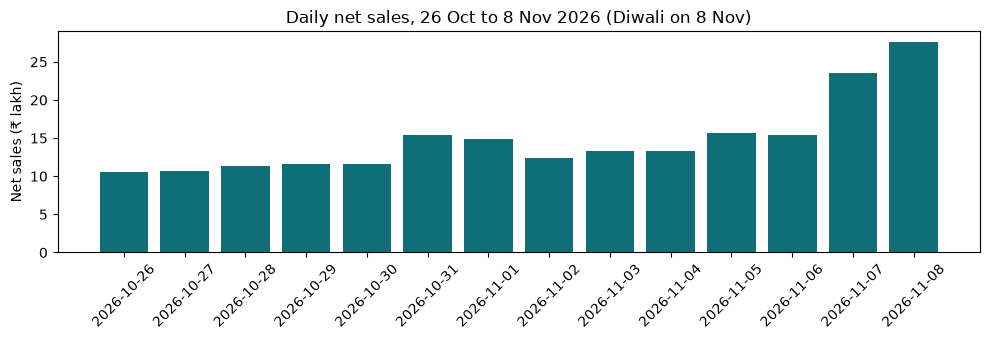

In [16]:
import matplotlib.pyplot as plt

pdf = spark.table("daily_sales").orderBy("sale_date").toPandas()
fig, ax = plt.subplots(figsize=(10, 3.5))
# Spark decimals arrive as Python Decimal objects: convert to float for plotting
ax.bar(pdf["sale_date"].astype(str), pdf["net_sales_inr"].astype(float) / 1e5, color="#0f6e78")
ax.set_ylabel("Net sales (₹ lakh)")
ax.set_title("Daily net sales, 26 Oct to 8 Nov 2026 (Diwali on 8 Nov)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 5. Proof of partition pruning

The physical plan lists `PartitionFilters`. Spark lists only the `year=2026/week=45` folder in GCS.

In [17]:
spark.sql("select sum(net_amount) from mart.fact_sales where year = 2026 and week = 45").explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[], functions=[sum(net_amount#778)])
   +- Exchange SinglePartition, ENSURE_REQUIREMENTS, [plan_id=652]
      +- HashAggregate(keys=[], functions=[partial_sum(net_amount#778)])
         +- Project [net_amount#778]
            +- FileScan parquet spark_catalog.mart.fact_sales[net_amount#778,year#785,week#786] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[gs://fmcg-mart/fact_sales/year=2026/week=45], PartitionFilters: [isnotnull(year#785), isnotnull(week#786), (year#785 = 2026), (week#786 = 45)], PushedFilters: [], ReadSchema: struct<net_amount:decimal(14,2)>




## 6. Browse the buckets with `gsutil` / `gcloud storage`

Shell commands work in cells with `!`. The kernel points the Google Cloud CLI at the local GCS emulator through a separate gcloud configuration (`fmcg-emulator`), so your default gcloud setup is untouched. With real GCS, the same commands run against your project.

In [18]:
!gsutil ls -lh gs://fmcg-datalake/

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.


                                  gs://fmcg-datalake/_manifests/
                                  gs://fmcg-datalake/customers/
                                  gs://fmcg-datalake/promotions/
                                  gs://fmcg-datalake/stores/
                                  gs://fmcg-datalake/transactions/
TOTAL: 0 objects, 0 bytes (0 B)


In [19]:
!gsutil du -sh gs://fmcg-landing gs://fmcg-datalake gs://fmcg-mart

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.


929.86 KiB   gs://fmcg-landing


1.16 MiB     gs://fmcg-datalake


1.72 MiB     gs://fmcg-mart


In [20]:
# the raw daily drops in the landing bucket
!gsutil ls -l gs://fmcg-landing/transactions/2026/11/08/ gs://fmcg-landing/customers/2026/11/08/

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.


    120837  2026-11-12T18:38:32Z  gs://fmcg-landing/transactions/2026/11/08/transactions_20261108.csv.gz
TOTAL: 1 objects, 120837 bytes (118 KiB)
       832  2026-11-12T18:38:32Z  gs://fmcg-landing/customers/2026/11/08/customers_20261108.csv.gz
TOTAL: 1 objects, 832 bytes (832 B)


In [21]:
# one datalake partition = one GCS folder of Parquet files
!gsutil ls -lh gs://fmcg-datalake/transactions/year=2026/month=11/day=8/

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.


       0 B  2026-11-12T18:38:40Z  gs://fmcg-datalake/transactions/year=2026/month=11/day=8/_SUCCESS
117.94 KiB  2026-11-12T18:38:39Z  gs://fmcg-datalake/transactions/year=2026/month=11/day=8/part-00000-7fdca8b9-6546-4f4c-952b-4e52d65b37b4-c000.snappy.parquet
TOTAL: 2 objects, 120774 bytes (117.94 KiB)


In [22]:
!gcloud storage ls gs://fmcg-mart/fact_sales/

gs://fmcg-mart/fact_sales/year=2026/


In [23]:
# the reconciliation manifest written by the mart job
!gsutil cat gs://fmcg-mart/_manifests/2026/W45/manifest_20261108.json

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.


{
  "run_date": "2026-11-08",
  "iso_year": 2026,
  "iso_week": 45,
  "week_start": "2026-11-02",
  "written_at": "2026-11-12T18:38:57.934194+00:00",
  "row_counts": {
    "fact_sales": 31335,
    "store_weekly_performance": 46,
    "category_brand_weekly": 29,
    "promotion_weekly_effectiveness": 8,
    "customer_tier_weekly": 5
  },
  "net_sales": 12127802.61,
  "checks": {
    "duplicates_removed": 154,
    "store_total_matches_fact": true,
    "category_total_matches_fact": true,
    "tier_total_matches_fact": true,
    "every_line_has_store": true
  }
}

In [24]:
# Spark can read the raw .csv.gz straight from the landing bucket too
(spark.read.option("header", True)
      .csv("gs://fmcg-landing/transactions/2026/11/08/transactions_20261108.csv.gz")
      .select("transaction_id", "store_id", "product_name", "quantity", "unit_price", "payment_mode")
      .show(5, 0))

+----------------+--------+----------------+--------+----------+------------+
|transaction_id  |store_id|product_name    |quantity|unit_price|payment_mode|
+----------------+--------+----------------+--------+----------+------------+
|T202611080140063|ST014   |Sandal Glow Soap|1       |180.0     |Wallet      |
|T202611080010030|ST001   |Basmati Rice    |4       |650.0     |UPI         |
|T202611080050000|ST005   |Atta Noodles    |1       |70.0      |Wallet      |
|T202611080350037|ST035   |Room Freshener  |1       |225.0     |UPI         |
|T202611080360031|ST036   |Herbal Shampoo  |1       |449.0     |Cash        |
+----------------+--------+----------------+--------+----------+------------+
only showing top 5 rows
